# Wetteranalyse: Berlin 2025

Dieses Notebook analysiert tägliche Wetterdaten für Berlin im Kalenderjahr 2025. Open-Meteo wird mit Beobachtungen der DWD-Station Berlin-Tempelhof (00433) verglichen.

## Vorbereitung und Zeitraum

Benötigt werden `pandas` und `matplotlib`. Installiere sie bei Bedarf in einer Notebook-Zelle mit `%pip install pandas matplotlib` und starte den Kernel anschließend neu. NumPy wird als Abhängigkeit von pandas mitinstalliert.

Untersucht wird ausschließlich der Zeitraum vom 1. Januar bis zum 31. Dezember 2025. Open-Meteo wird an den Koordinaten der DWD-Station Berlin-Tempelhof abgefragt, damit die Orte möglichst gut vergleichbar sind.

In [1]:
from urllib.parse import urlencode
from urllib.request import urlopen
import io
import json
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

latitude = 52.4676
longitude = 13.4020
start_date = "2025-01-01"
end_date = "2025-12-31"

print(f"Berlin-Tempelhof: {start_date} bis {end_date}")

Berlin-Tempelhof: 2025-01-01 bis 2025-12-31


## Open-Meteo-Daten abrufen

Open-Meteo liefert tägliche Modell-/Reanalysewerte für dieselben Koordinaten wie die DWD-Station. Der Abruf benötigt eine Internetverbindung und keinen API-Schlüssel. Temperaturen sind in °C, Niederschlag in mm und Windgeschwindigkeit in km/h.

In [2]:
parameter = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date,
    "end_date": end_date,
    "daily": "temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_max",
    "timezone": "Europe/Berlin",
}
url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(parameter)

with urlopen(url, timeout=30) as antwort:
    daten = json.loads(antwort.read().decode("utf-8"))

if daten.get("error"):
    raise RuntimeError(daten.get("reason", "Die Wetterdaten konnten nicht geladen werden."))

weather = pd.DataFrame(daten["daily"]).rename(columns={
    "time": "Datum",
    "temperature_2m_max": "Max. Temperatur (°C)",
    "temperature_2m_min": "Min. Temperatur (°C)",
    "temperature_2m_mean": "Mittlere Temperatur (°C)",
    "precipitation_sum": "Niederschlag (mm)",
    "wind_speed_10m_max": "Max. Wind (km/h)",
})
weather["Datum"] = pd.to_datetime(weather["Datum"])
weather = weather.set_index("Datum").sort_index()

print(f"Open-Meteo: {len(weather):,} Tageswerte")
display(weather.head())

Open-Meteo: 365 Tageswerte


,Max. Temperatur (°C),Min. Temperatur (°C),Mittlere Temperatur (°C),Niederschlag (mm),Max. Wind (km/h)
Datum,,,,,
2025-01-01,7.0,0.5,4.8,0.1,26.1
2025-01-02,6.9,1.0,4.1,3.9,25.7
2025-01-03,2.6,-1.3,1.0,4.6,29.4
2025-01-04,0.9,-2.3,-0.9,0.0,19.5
2025-01-05,1.8,-2.4,-1.0,9.4,18.2


## DWD-Daten laden und auf 2025 begrenzen

Vergleichsquelle ist der DWD-CDC-Tagesdatensatz der Station Berlin-Tempelhof (00433). Verglichen werden Tagesmittel-, Höchst- und Tiefsttemperatur sowie Niederschlag. Wind bleibt in der Open-Meteo-Auswertung, da die hier gewählten DWD-Felder keine direkt gleich definierte Windgröße enthalten.

In [3]:
dwd_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/daily/kl/historical/"
    "tageswerte_KL_00433_19480101_20251231_hist.zip"
)
with urlopen(dwd_url, timeout=60) as antwort:
    dwd_zip = zipfile.ZipFile(io.BytesIO(antwort.read()))

produktdatei = next(
    name for name in dwd_zip.namelist()
    if name.startswith("produkt_klima_tag_") and name.endswith("_00433.txt")
)
dwd_roh = pd.read_csv(
    dwd_zip.open(produktdatei),
    sep=";",
    skipinitialspace=True,
    na_values=[-999, "-999"],
    low_memory=False,
)
dwd_roh.columns = dwd_roh.columns.str.strip()
dwd_roh = dwd_roh.loc[dwd_roh["MESS_DATUM"].between(20250101, 20251231)].copy()
dwd_roh["Datum"] = pd.to_datetime(dwd_roh["MESS_DATUM"].astype(str), format="%Y%m%d")

dwd = dwd_roh.set_index("Datum")[["TMK", "TXK", "TNK", "RSK"]].rename(columns={
    "TMK": "DWD Mitteltemperatur (°C)",
    "TXK": "DWD Max. Temperatur (°C)",
    "TNK": "DWD Min. Temperatur (°C)",
    "RSK": "DWD Niederschlag (mm)",
})

vergleich = weather.join(dwd, how="inner")
print(f"DWD-Tageswerte 2025: {len(dwd):,}; gemeinsame Tage: {len(vergleich):,}")
display(vergleich.head())

DWD-Tageswerte 2025: 365; gemeinsame Tage: 365


,Max. Temperatur (°C),Min. Temperatur (°C),Mittlere Temperatur (°C),Niederschlag (mm),Max. Wind (km/h),DWD Mitteltemperatur (°C),DWD Max. Temperatur (°C),DWD Min. Temperatur (°C),DWD Niederschlag (mm)
Datum,,,,,,,,,
2025-01-01,7.0,0.5,4.8,0.1,26.1,5.5,8.5,2.0,0.8
2025-01-02,6.9,1.0,4.1,3.9,25.7,4.6,8.4,2.0,0.2
2025-01-03,2.6,-1.3,1.0,4.6,29.4,1.4,3.8,-1.0,0.4
2025-01-04,0.9,-2.3,-0.9,0.0,19.5,0.0,0.6,-0.8,0.0
2025-01-05,1.8,-2.4,-1.0,9.4,18.2,-0.8,1.2,-2.6,10.9


## Open-Meteo mit DWD vergleichen

Die mittlere Abweichung ist Open-Meteo minus DWD; ein positiver Wert bedeutet also höhere Open-Meteo-Werte. Der mittlere absolute Fehler (MAE) zeigt die typische Abweichungsgröße unabhängig vom Vorzeichen.

In [4]:
messgroessen = {
    "Mittlere Temperatur (°C)": "DWD Mitteltemperatur (°C)",
    "Max. Temperatur (°C)": "DWD Max. Temperatur (°C)",
    "Min. Temperatur (°C)": "DWD Min. Temperatur (°C)",
    "Niederschlag (mm)": "DWD Niederschlag (mm)",
}
kennzahlen = []
for open_meteo_spalte, dwd_spalte in messgroessen.items():
    abweichung = vergleich[open_meteo_spalte] - vergleich[dwd_spalte]
    kennzahlen.append({
        "Messgröße": open_meteo_spalte,
        "Mittlere Abweichung": abweichung.mean(),
        "Mittlerer absoluter Fehler": abweichung.abs().mean(),
    })

kennzahlen = pd.DataFrame(kennzahlen).set_index("Messgröße")
display(kennzahlen.round(2))

,Mittlere Abweichung,Mittlerer absoluter Fehler
Messgröße,,
Mittlere Temperatur (°C),-0.30,0.59
Max. Temperatur (°C),-0.78,1.02
Min. Temperatur (°C),0.38,0.88
Niederschlag (mm),0.38,1.07


### Grafischer Vergleich

Der Streuplot vergleicht die täglichen Mitteltemperaturen; Punkte auf der Diagonalen stimmen überein. Die Monatsplots zeigen Temperaturmittel und Niederschlagssummen beider Quellen.

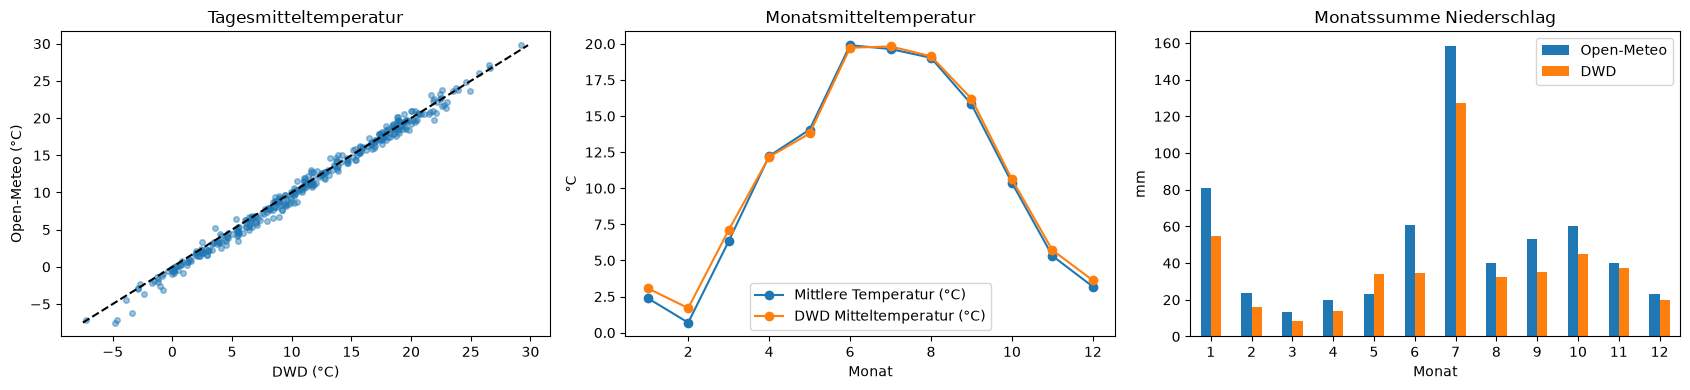

In [5]:
monatstemperatur = vergleich[[
    "Mittlere Temperatur (°C)", "DWD Mitteltemperatur (°C)"
]].groupby(vergleich.index.month).mean()
monatsniederschlag = vergleich[[
    "Niederschlag (mm)", "DWD Niederschlag (mm)"
]].groupby(vergleich.index.month).sum()

fig, achsen = plt.subplots(1, 3, figsize=(17, 4))

x = vergleich["DWD Mitteltemperatur (°C)"]
y = vergleich["Mittlere Temperatur (°C)"]
achsen[0].scatter(x, y, alpha=0.45, s=16)
grenzen = [min(x.min(), y.min()), max(x.max(), y.max())]
achsen[0].plot(grenzen, grenzen, color="black", linestyle="--")
achsen[0].set_title("Tagesmitteltemperatur")
achsen[0].set_xlabel("DWD (°C)")
achsen[0].set_ylabel("Open-Meteo (°C)")

monatstemperatur.plot(ax=achsen[1], marker="o")
achsen[1].set_title("Monatsmitteltemperatur")
achsen[1].set_xlabel("Monat")
achsen[1].set_ylabel("°C")

monatsniederschlag.rename(columns={
    "Niederschlag (mm)": "Open-Meteo",
    "DWD Niederschlag (mm)": "DWD",
}).plot(ax=achsen[2], kind="bar")
achsen[2].set_title("Monatssumme Niederschlag")
achsen[2].set_xlabel("Monat")
achsen[2].set_ylabel("mm")
achsen[2].tick_params(axis="x", labelrotation=0)

fig.tight_layout()
plt.show()

## Datenüberblick und Kennzahlen

Zuerst prüfen wir Umfang und fehlende Werte. Danach berechnen wir Monatsmittel, Niederschlagssummen sowie die Zahl heißer und niederschlagsreicher Tage.

In [6]:
print("Fehlende Werte je Spalte:")
display(weather.isna().sum().to_frame("Fehlende Werte"))

print("Zusammenfassung:")
display(weather.describe().T)

heisse_tage = int((weather["Max. Temperatur (°C)"] >= 30).sum())
regentage = int((weather["Niederschlag (mm)"] >= 1).sum())
print(f"Tage mit mindestens 30 °C: {heisse_tage}")
print(f"Tage mit mindestens 1 mm Niederschlag: {regentage}")

monthly = weather.groupby(weather.index.to_period("M")).agg({
    "Mittlere Temperatur (°C)": "mean",
    "Niederschlag (mm)": "sum",
    "Max. Wind (km/h)": "mean",
})
display(monthly.tail(12).round(1))

Fehlende Werte je Spalte:


,Fehlende Werte
Max. Temperatur (°C),0
Min. Temperatur (°C),0
Mittlere Temperatur (°C),0
Niederschlag (mm),0
Max. Wind (km/h),0


Zusammenfassung:


,count,mean,std,min,25%,50%,75%,max
Max. Temperatur (°C),365.0,14.832877,8.416785,-4.4,7.9,15.0,21.7,37.3
Min. Temperatur (°C),365.0,6.850411,6.694654,-13.0,1.5,6.7,12.6,20.6
Mittlere Temperatur (°C),365.0,10.801096,7.478184,-7.5,4.9,11.0,17.3,29.8
Niederschlag (mm),365.0,1.633973,3.596205,0.0,0.0,0.1,1.6,41.5
Max. Wind (km/h),365.0,15.318904,5.085381,5.1,11.6,14.9,18.5,32.7


Tage mit mindestens 30 °C: 9
Tage mit mindestens 1 mm Niederschlag: 119


,Mittlere Temperatur (°C),Niederschlag (mm),Max. Wind (km/h)
Datum,,,
2025-01,2.4,81.0,18.1
2025-02,0.7,23.7,12.2
2025-03,6.3,13.6,12.2
2025-04,12.2,19.7,14.3
2025-05,14.1,23.3,17.3
2025-06,19.9,60.5,19.3
2025-07,19.6,158.4,15.4
2025-08,19.0,39.8,13.5
2025-09,15.8,53.2,15.4


## Temperatur- und Niederschlagsverlauf

Der Temperaturplot glättet kurzfristige Schwankungen mit einem gleitenden 30-Tage-Mittel. Der zweite Plot zeigt die monatlichen Niederschlagssummen.

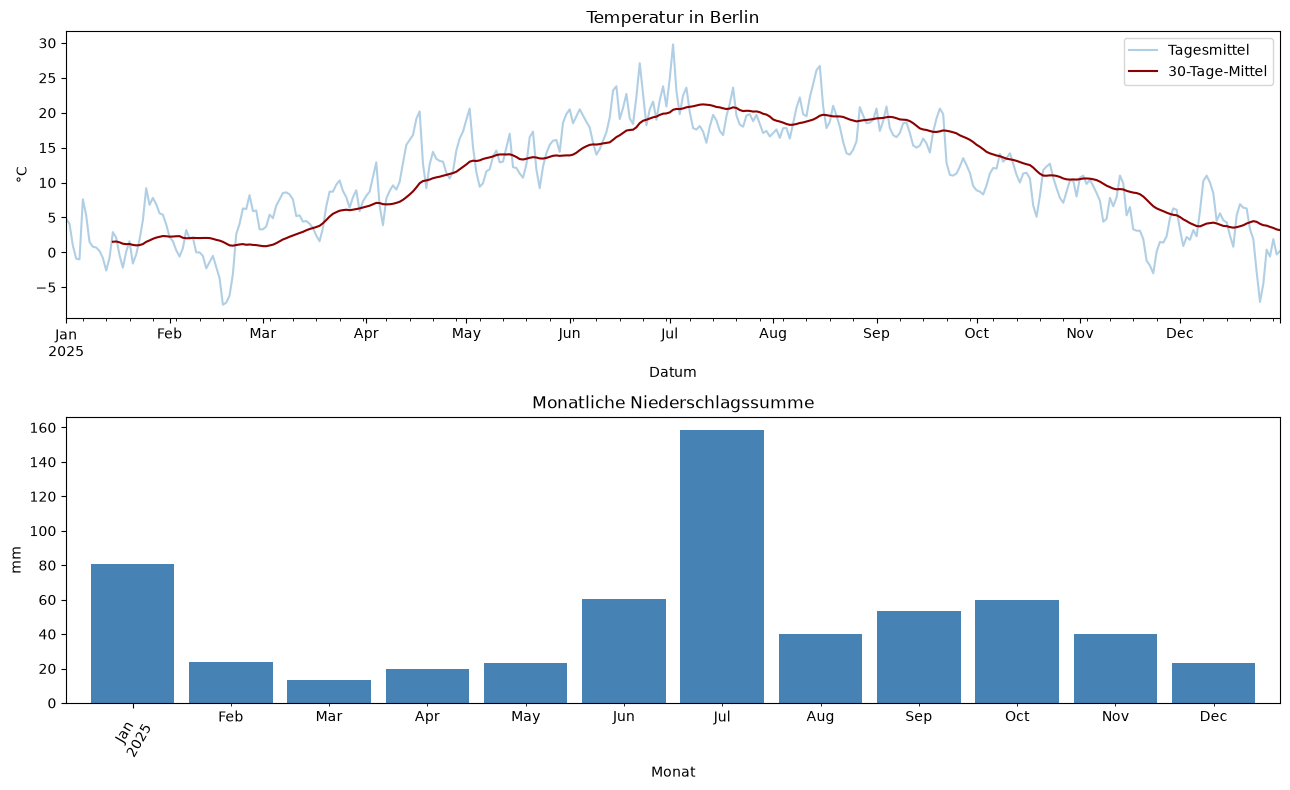

In [7]:
fig, achsen = plt.subplots(2, 1, figsize=(13, 8), sharex=False)

weather["Mittlere Temperatur (°C)"].plot(ax=achsen[0], alpha=0.35, label="Tagesmittel")
weather["Mittlere Temperatur (°C)"].rolling(30, min_periods=15).mean().plot(
    ax=achsen[0], color="darkred", label="30-Tage-Mittel"
)
achsen[0].set_title("Temperatur in Berlin")
achsen[0].set_ylabel("°C")
achsen[0].legend()

monthly["Niederschlag (mm)"].rename_axis("Monat").plot(
    ax=achsen[1], kind="bar", color="steelblue", width=0.85
)
achsen[1].set_title("Monatliche Niederschlagssumme")
achsen[1].set_ylabel("mm")
achsen[1].set_xlabel("Monat")
achsen[1].tick_params(axis="x", labelrotation=60)

fig.tight_layout()
plt.show()

## Quartale und Extremwerte

Die Quartalsauswertung vergleicht mittlere Temperatur, Niederschlag und Wind für Q1 bis Q4 des Jahres 2025. Zusätzlich zeigen wir die wärmsten Tage und die höchsten täglichen Niederschlagsmengen.

In [8]:
quartale = weather.assign(Quartal=weather.index.quarter).groupby("Quartal").agg({
    "Mittlere Temperatur (°C)": "mean",
    "Niederschlag (mm)": "sum",
    "Max. Wind (km/h)": "mean",
})
quartale.index = [f"Q{quartal}" for quartal in quartale.index]
quartale = quartale.rename(columns={"Niederschlag (mm)": "Niederschlag gesamt (mm)"})
print("Kennzahlen nach Kalenderquartal:")
display(quartale.round(1))

print("Wärmste Tage:")
display(weather.nlargest(5, "Max. Temperatur (°C)")[["Max. Temperatur (°C)", "Niederschlag (mm)"]])

print("Tage mit dem meisten Niederschlag:")
display(weather.nlargest(5, "Niederschlag (mm)")[["Niederschlag (mm)", "Max. Temperatur (°C)"]])

Kennzahlen nach Kalenderquartal:


,Mittlere Temperatur (°C),Niederschlag gesamt (mm),Max. Wind (km/h)
Q1,3.2,118.3,14.2
Q2,15.4,103.5,17.0
Q3,18.2,251.4,14.8
Q4,6.3,123.2,15.3


Wärmste Tage:


,Max. Temperatur (°C),Niederschlag (mm)
Datum,,
2025-07-02,37.3,0.0
2025-06-22,34.1,0.0
2025-08-14,33.4,0.0
2025-08-15,33.3,0.4
2025-07-01,33.0,0.0


Tage mit dem meisten Niederschlag:


,Niederschlag (mm),Max. Temperatur (°C)
Datum,,
2025-07-21,41.5,22.1
2025-07-12,22.8,17.4
2025-07-23,16.3,21.0
2025-01-09,16.1,1.3
2025-09-02,14.7,20.5


## Ergebnisse speichern

Optional kannst du den auf gemeinsamen Tagen basierenden Open-Meteo-/DWD-Vergleich als CSV im aktuellen Arbeitsverzeichnis speichern.

In [9]:
ausgabe = "berlin_wettervergleich_2025.csv"
vergleich.to_csv(ausgabe, index_label="Datum")
print(f"Gespeichert: {ausgabe}")

Gespeichert: berlin_wettervergleich_2025.csv
